In [ ]:
# 1. Download Bijie Dataset
!kaggle datasets download -d ksncik/bijie-landslide-dataset
!mkdir -p /content/bijie_data
!unzip -q -o bijie-landslide-dataset.zip -d /content/bijie_data

import os
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF
import numpy as np
import matplotlib.pyplot as plt

# Connect to T4 GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Hardware Accelerator: {device}")

# Auto-detect the correct image and mask folders
BIJIE_IMG_DIR = None
BIJIE_MASK_DIR = None

for root, dirs, files in os.walk('/content/bijie_data'):
    folder_name = os.path.basename(root).lower()
    if 'image' in folder_name and any(f.endswith('.png') for f in files):
        BIJIE_IMG_DIR = root
    elif 'mask' in folder_name and any(f.endswith('.png') for f in files):
        BIJIE_MASK_DIR = root

print(f"Auto-Detected Image Directory: {BIJIE_IMG_DIR}")
print(f"Auto-Detected Mask Directory: {BIJIE_MASK_DIR}")

if not BIJIE_IMG_DIR or not BIJIE_MASK_DIR:
    raise FileNotFoundError("Could not auto-detect the image or mask folders. Please check the Colab file explorer.")

class BijieDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        # Ensure we only grab valid images
        self.images = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])
        self.masks = sorted([f for f in os.listdir(mask_dir) if f.endswith('.png')])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        # Load 3-channel RGB image and 1-channel grayscale mask
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize to standard 256x256
        image = image.resize((256, 256))
        mask = mask.resize((256, 256))

        image = TF.to_tensor(image)
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float() # Strict binary conversion

        return image, mask

dataset = BijieDataset(BIJIE_IMG_DIR, BIJIE_MASK_DIR)
train_len = int(0.8 * len(dataset))
val_len = len(dataset) - train_len
train_data, val_data = random_split(dataset, [train_len, val_len])

train_loader = DataLoader(train_data, batch_size=8, shuffle=True)
val_loader = DataLoader(val_data, batch_size=8, shuffle=False)
print(f"Bijie Pipeline Ready: {train_len} Training, {val_len} Validation.")

Dataset URL: https://www.kaggle.com/datasets/ksncik/bijie-landslide-dataset
License(s): unknown
bijie-landslide-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Hardware Accelerator: cuda
Auto-Detected Image Directory: /content/bijie_data/Bijie-landslide-dataset/landslide/image
Auto-Detected Mask Directory: /content/bijie_data/Bijie-landslide-dataset/landslide/mask
Bijie Pipeline Ready: 616 Training, 154 Validation.


In [ ]:
def calculate_iou(preds, real_masks):
    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()
    preds = preds.view(-1)
    trues = real_masks.view(-1)
    intersection = (preds * trues).sum()
    union = preds.sum() + trues.sum() - intersection
    if union == 0: return 1.0 if intersection == 0 else 0.0
    return (intersection / union).item()

def show_predictions(model, val_loader, title):
    model.eval()
    images, real_masks = next(iter(val_loader))
    images = images.to(device)
    with torch.no_grad():
        preds = torch.sigmoid(model(images)).cpu().numpy()

    images = images.cpu().numpy()
    real_masks = real_masks.cpu().numpy()

    fig, axes = plt.subplots(4, 3, figsize=(10, 12))
    fig.suptitle(title, fontsize=16)

    for i in range(4):
        # Matplotlib expects images in (H, W, Channels) format
        img_vis = images[i].transpose(1, 2, 0)
        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title("Satellite (RGB)")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(real_masks[i, 0], cmap='gray')
        axes[i, 1].set_title("True Mask")
        axes[i, 1].axis('off')

        axes[i, 2].imshow(preds[i, 0], cmap='magma', vmin=0, vmax=1)
        axes[i, 2].set_title("AI Prediction")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

--- TRAINING MODEL 1: CUSTOM CNN ---
Epoch 1/10 - Loss: 1.4546
Epoch 2/10 - Loss: 1.1788
Epoch 3/10 - Loss: 1.1473
Epoch 4/10 - Loss: 1.1369
Epoch 5/10 - Loss: 1.1392
Epoch 6/10 - Loss: 1.1316
Epoch 7/10 - Loss: 1.1320
Epoch 8/10 - Loss: 1.1192
Epoch 9/10 - Loss: 1.1225
Epoch 10/10 - Loss: 1.1204
✅ Model 1 (CNN) Final IoU: 20.18%


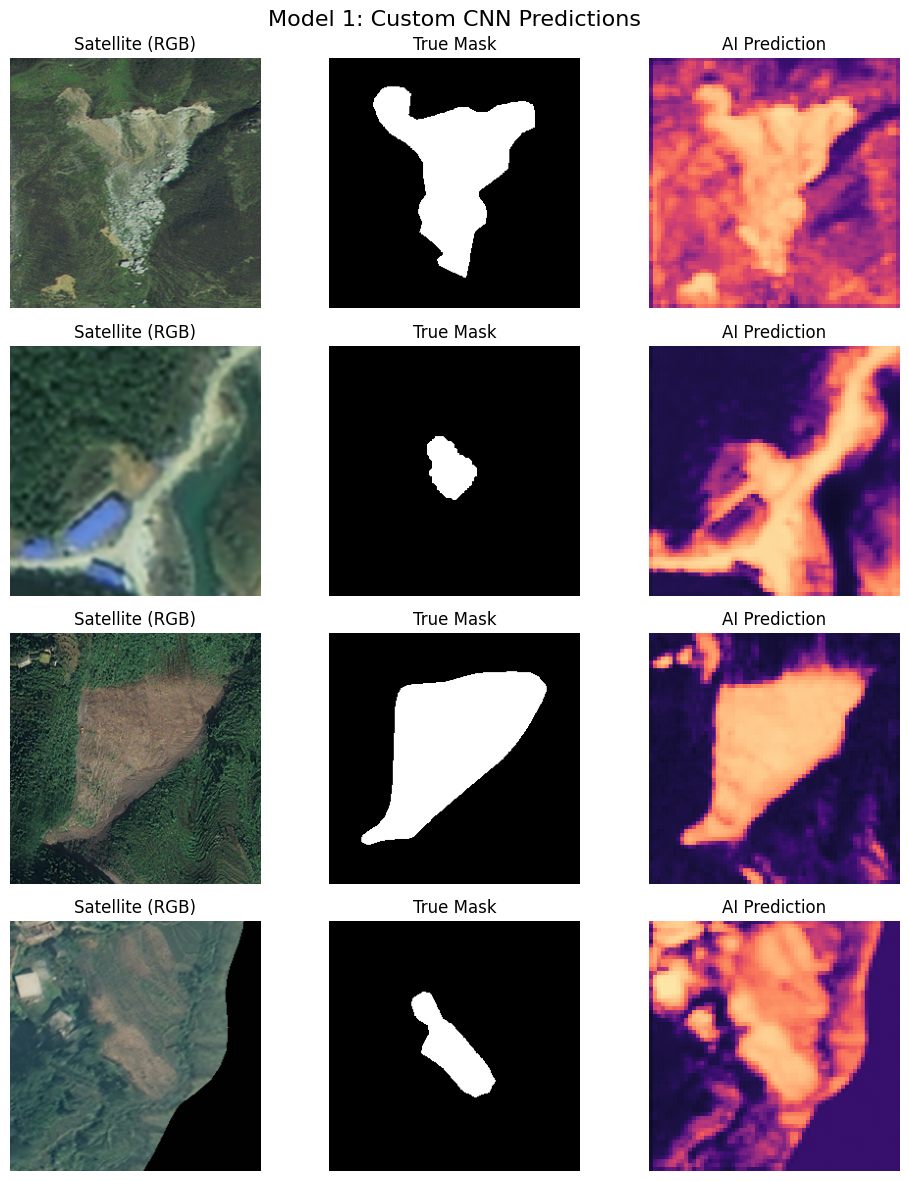

In [ ]:
class CustomLandslideCNN(nn.Module):
    def __init__(self):
        super(CustomLandslideCNN, self).__init__()
        # Input is now 3 channels (RGB)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ReLU(),
            nn.ConvTranspose2d(32, 32, 2, stride=2), nn.ReLU(),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

print("--- TRAINING MODEL 1: CUSTOM CNN ---")
model1 = CustomLandslideCNN().to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([15.0]).to(device))
optimizer1 = optim.Adam(model1.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    model1.train()
    running_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer1.zero_grad()
        loss = criterion(model1(images), masks)
        loss.backward()
        optimizer1.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

model1.eval()
total_iou = 0.0
with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        total_iou += calculate_iou(model1(images), masks)

print(f"✅ Model 1 (CNN) Final IoU: {total_iou / len(val_loader) * 100:.2f}%")
show_predictions(model1, val_loader, "Model 1: Custom CNN Predictions")

--- TRAINING MODEL 2: U-NET BASELINE ---
Epoch 1/10 - Loss: 1.3309
Epoch 2/10 - Loss: 1.1699
Epoch 3/10 - Loss: 1.1727
Epoch 4/10 - Loss: 1.1172
Epoch 5/10 - Loss: 1.1292
Epoch 6/10 - Loss: 1.1512
Epoch 7/10 - Loss: 1.0615
Epoch 8/10 - Loss: 1.1738
Epoch 9/10 - Loss: 1.1121
Epoch 10/10 - Loss: 1.0591
✅ Model 2 (U-Net) Final IoU: 24.41%


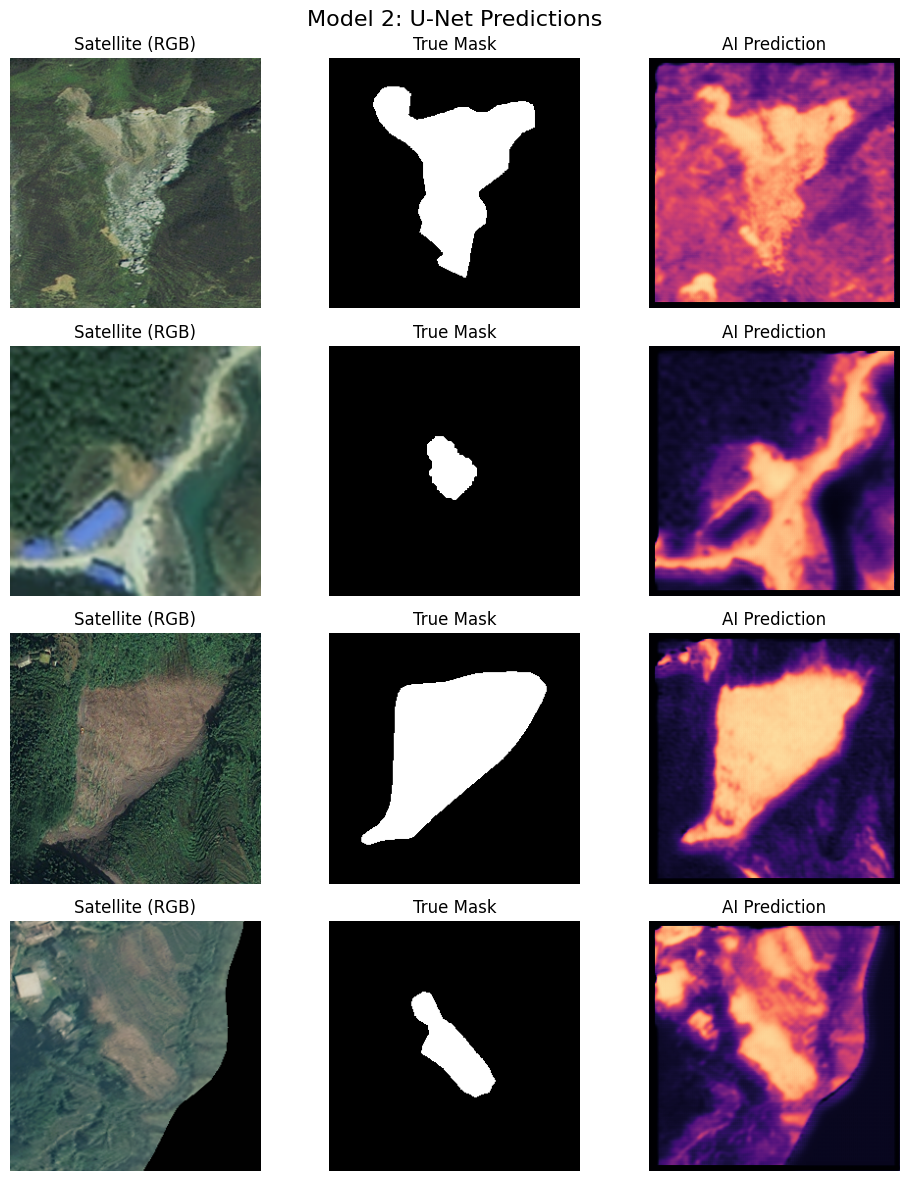

In [ ]:
class UNetBaseline(nn.Module):
    def __init__(self):
        super(UNetBaseline, self).__init__()
        # Input is 3 channels
        self.down1 = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.down2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.Conv2d(128, 128, 3, padding=1), nn.ReLU())
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up1 = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up2 = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU())
        self.final_conv = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        d1 = self.down1(x)
        x = self.pool1(d1)
        d2 = self.down2(x)
        x = self.pool2(d2)
        x = self.bottleneck(x)
        x = self.up1(x)
        x = torch.cat([x, d2], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = torch.cat([x, d1], dim=1)
        x = self.conv_up2(x)
        return self.final_conv(x)

print("--- TRAINING MODEL 2: U-NET BASELINE ---")
model2 = UNetBaseline().to(device)
optimizer2 = optim.Adam(model2.parameters(), lr=0.001)

for epoch in range(epochs):
    model2.train()
    running_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer2.zero_grad()
        loss = criterion(model2(images), masks)
        loss.backward()
        optimizer2.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

model2.eval()
total_iou = 0.0
with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        total_iou += calculate_iou(model2(images), masks)

print(f"✅ Model 2 (U-Net) Final IoU: {total_iou / len(val_loader) * 100:.2f}%")
show_predictions(model2, val_loader, "Model 2: U-Net Predictions")

In [ ]:
import torch
import torch.nn as nn

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, inputs, targets):
        # Convert raw AI output into a probability between 0 and 1
        inputs = torch.sigmoid(inputs)

        # Flatten the 2D images into 1D arrays for fast math
        inputs = inputs.view(-1)
        targets = targets.view(-1)

        # Calculate the overlap (intersection)
        intersection = (inputs * targets).sum()

        # Calculate the Dice coefficient (similar to IoU)
        dice = (2. * intersection + self.smooth) / (inputs.sum() + targets.sum() + self.smooth)

        # The AI's goal is to minimize loss, so we subtract the score from 1
        return 1 - dice

print("✅ Dice Loss Rubric Created!")

✅ Dice Loss Rubric Created!


In [ ]:
import torchvision.transforms.functional as TF
import random
from torch.utils.data import Dataset, DataLoader, random_split
import os
from PIL import Image

class AugmentedBijieDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])
        self.masks = sorted([f for f in os.listdir(mask_dir) if f.endswith('.png')])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        # Load and resize
        image = Image.open(img_path).convert("RGB").resize((256, 256))
        mask = Image.open(mask_path).convert("L").resize((256, 256))

        # DATA AUGMENTATION: 50% chance to flip horizontally
        if random.random() > 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # DATA AUGMENTATION: 50% chance to flip vertically
        if random.random() > 0.5:
            image = TF.vflip(image)
            mask = TF.vflip(mask)

        # Convert to Tensor and Binary Mask
        image = TF.to_tensor(image)
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()

        return image, mask

# Rebuild the data loaders using the previously auto-detected directories
augmented_dataset = AugmentedBijieDataset(BIJIE_IMG_DIR, BIJIE_MASK_DIR)
train_len = int(0.8 * len(augmented_dataset))
val_len = len(augmented_dataset) - train_len
train_data, val_data = random_split(augmented_dataset, [train_len, val_len])

train_loader = DataLoader(train_data, batch_size=8, shuffle=True)
val_loader = DataLoader(val_data, batch_size=8, shuffle=False)

print(f"✅ Augmented Pipeline Ready: {train_len} Training, {val_len} Validation.")

✅ Augmented Pipeline Ready: 616 Training, 154 Validation.


In [ ]:
import torch.optim as optim

# Re-initialize a fresh U-Net model
model = UNetBaseline().to(device)

# Swap out BCE for our new custom Dice Loss
criterion = DiceLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
patience = 10  # Stop if no improvement for 10 epochs
best_loss = float('inf')
epochs_no_improve = 0

print("--- STARTING ADVANCED TRAINING (DICE LOSS + AUGMENTATION) ---")
for epoch in range(epochs):
    # 1. Training Phase
    model.train()
    running_train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), masks)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)

    # 2. Validation Phase (Early Stopping Check)
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for val_images, val_masks in val_loader:
            val_images, val_masks = val_images.to(device), val_masks.to(device)
            v_loss = criterion(model(val_images), val_masks)
            running_val_loss += v_loss.item()

    avg_val_loss = running_val_loss / len(val_loader)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    # 3. Save Best Model or Stop Early
    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), 'best_unet_weights.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"🛑 Early stopping triggered! No improvement for {patience} epochs.")
            break

# Load the mathematically best weights back into the model before final grading
model.load_state_dict(torch.load('best_unet_weights.pth'))
print("✅ Best weights restored to the model.")

--- STARTING ADVANCED TRAINING (DICE LOSS + AUGMENTATION) ---
Epoch 1/50 | Train Loss: 0.6665 | Val Loss: 0.6523
Epoch 2/50 | Train Loss: 0.5747 | Val Loss: 0.5754
Epoch 3/50 | Train Loss: 0.9467 | Val Loss: 1.0000
Epoch 4/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 5/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 6/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 7/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 8/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 9/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 10/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 11/50 | Train Loss: 1.0000 | Val Loss: 1.0000
Epoch 12/50 | Train Loss: 1.0000 | Val Loss: 1.0000
🛑 Early stopping triggered! No improvement for 10 epochs.
✅ Best weights restored to the model.



--- FINAL EXAM FOR ADVANCED U-NET ---
✅ Advanced U-Net Final IoU: 27.40%


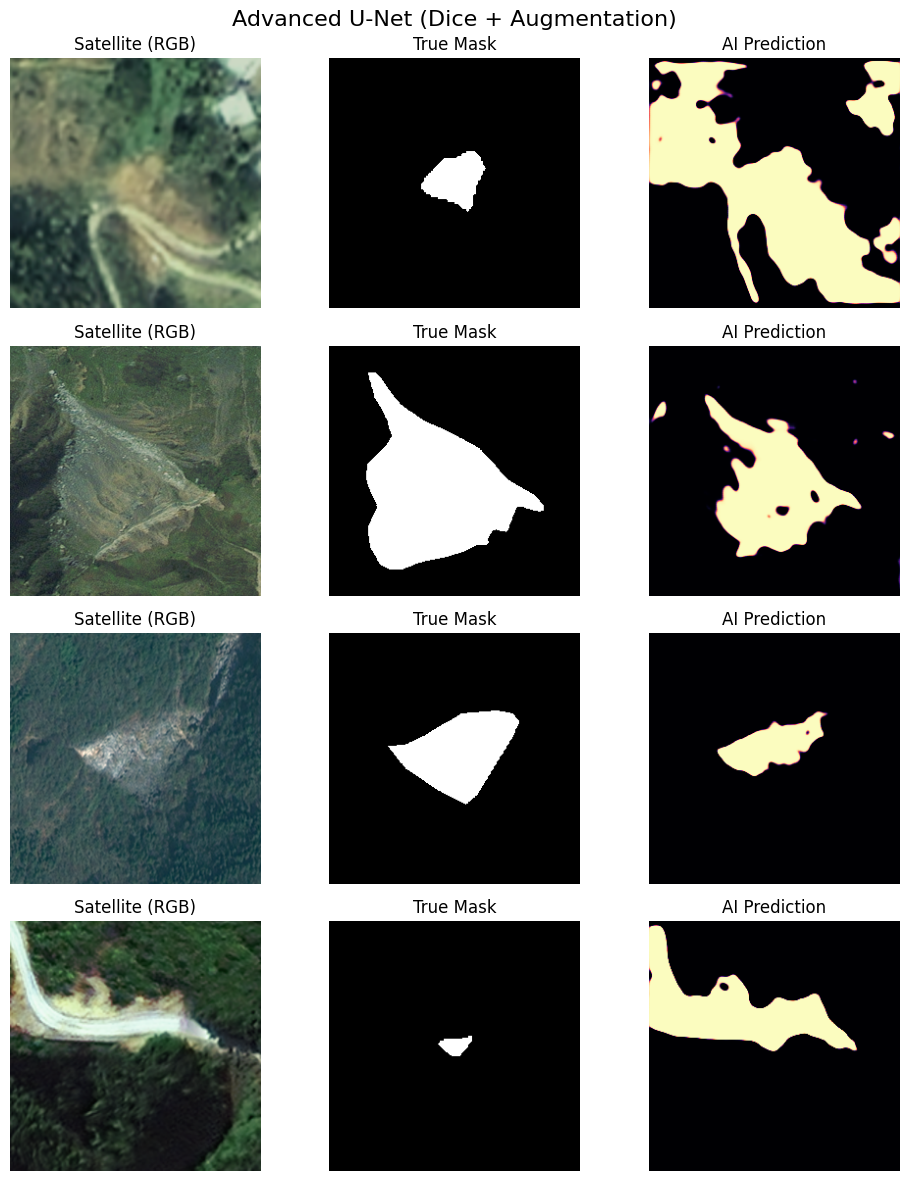

In [ ]:
print("\n--- FINAL EXAM FOR ADVANCED U-NET ---")
model.eval()
total_iou = 0.0
with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        total_iou += calculate_iou(model(images), masks)

print(f"✅ Advanced U-Net Final IoU: {total_iou / len(val_loader) * 100:.2f}%")
show_predictions(model, val_loader, "Advanced U-Net (Dice + Augmentation)")

In [ ]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.6 MB/s eta 0:00:00


In [ ]:
import segmentation_models_pytorch as smp
import torch.nn as nn
import torch.optim as optim
import torch

# 1. INITIALIZE PRE-TRAINED RESNET-34 U-NET
print("--- DOWNLOADING PRE-TRAINED RESNET-34 ---")
model = smp.Unet(
    encoder_name="resnet34",        # Use the powerful ResNet-34 backbone
    encoder_weights="imagenet",     # Use weights pre-trained on millions of images
    in_channels=3,                  # We are still using 3-channel RGB Bijie pictures
    classes=1,                      # 1 output class (landslide mask)
).to(device)

# 2. DEFINE THE HYBRID "COMBO" LOSS
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, inputs, targets):
        # Part A: BCE for smooth, stable learning
        bce_loss = self.bce(inputs, targets)

        # Part B: Dice for sharp boundaries
        inputs_sigmoid = torch.sigmoid(inputs)
        inputs_flat = inputs_sigmoid.view(-1)
        targets_flat = targets.view(-1)
        intersection = (inputs_flat * targets_flat).sum()
        dice_loss = 1 - (2. * intersection + 1e-6) / (inputs_flat.sum() + targets_flat.sum() + 1e-6)

        # Combine them for the final grade
        return bce_loss + dice_loss

criterion = BCEDiceLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005) # Slightly lower learning rate for pre-trained weights

# 3. ADVANCED TRAINING LOOP WITH EARLY STOPPING
epochs = 50
patience = 10
best_loss = float('inf')
epochs_no_improve = 0

print("--- STARTING RESNET-34 COMBO TRAINING ---")
for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), masks)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for val_images, val_masks in val_loader:
            val_images, val_masks = val_images.to(device), val_masks.to(device)
            v_loss = criterion(model(val_images), val_masks)
            running_val_loss += v_loss.item()

    avg_val_loss = running_val_loss / len(val_loader)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), 'best_resnet_unet.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"🛑 Early stopping triggered! No improvement for {patience} epochs.")
            break

model.load_state_dict(torch.load('best_resnet_unet.pth'))
print("✅ Best ResNet weights restored to the model.")

--- DOWNLOADING PRE-TRAINED RESNET-34 ---


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

--- STARTING RESNET-34 COMBO TRAINING ---
Epoch 1/50 | Train Loss: 0.6142 | Val Loss: 0.4311
Epoch 2/50 | Train Loss: 0.3685 | Val Loss: 0.3350
Epoch 3/50 | Train Loss: 0.3457 | Val Loss: 0.3133
Epoch 4/50 | Train Loss: 0.3093 | Val Loss: 0.2972
Epoch 5/50 | Train Loss: 0.2924 | Val Loss: 0.3424
Epoch 6/50 | Train Loss: 0.2849 | Val Loss: 0.3056
Epoch 7/50 | Train Loss: 0.2620 | Val Loss: 0.2774
Epoch 8/50 | Train Loss: 0.2606 | Val Loss: 0.4083
Epoch 9/50 | Train Loss: 0.2545 | Val Loss: 0.3021
Epoch 10/50 | Train Loss: 0.2428 | Val Loss: 0.2461
Epoch 11/50 | Train Loss: 0.2163 | Val Loss: 0.2488
Epoch 12/50 | Train Loss: 0.2143 | Val Loss: 0.2305
Epoch 13/50 | Train Loss: 0.2240 | Val Loss: 0.2422
Epoch 14/50 | Train Loss: 0.2080 | Val Loss: 0.2361
Epoch 15/50 | Train Loss: 0.2040 | Val Loss: 0.2834
Epoch 16/50 | Train Loss: 0.2054 | Val Loss: 0.2890
Epoch 17/50 | Train Loss: 0.1942 | Val Loss: 0.2501
Epoch 18/50 | Train Loss: 0.1915 | Val Loss: 0.2330
Epoch 19/50 | Train Loss: 0.184


--- FINAL EXAM FOR ADVANCED U-NET ---
✅ Advanced U-Net Final IoU: 78.01%


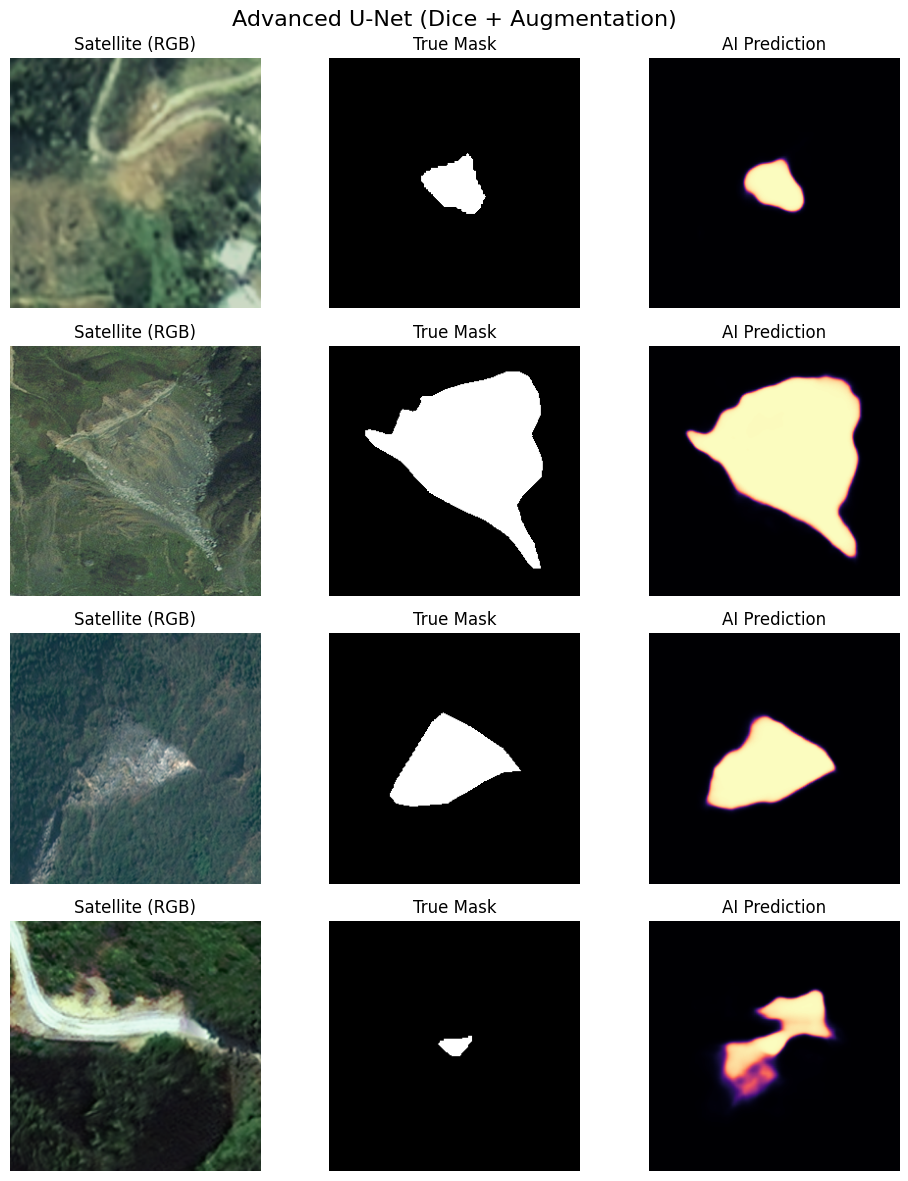

In [ ]:
print("\n--- FINAL EXAM FOR ADVANCED U-NET ---")
model.eval()
total_iou = 0.0
with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        total_iou += calculate_iou(model(images), masks)

print(f"✅ Advanced U-Net Final IoU: {total_iou / len(val_loader) * 100:.2f}%")
show_predictions(model, val_loader, "Advanced U-Net (Dice + Augmentation)")